In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
X = np.column_stack([np.loadtxt(f"v{i}.txt") for i in range(1,6)]) # shape (M,5)

1.1)

In [3]:

M,A = X.shape
true_means = X.mean(axis=0)
print("True means: ",true_means)
print("shape: ", (M,A))


True means:  [1.76083993 2.88634422 4.01184851 5.13711648 6.26238444]
shape:  (1600000, 5)


1.2)

In [4]:
def block_data(X,N):
  num_blocks = M//N
  return X.copy().reshape(num_blocks,N,A)

def analyze_sample_means(X,N,plot=True):
  X_blocked = block_data(X,N)
  # print("X_blockd shape: ",X_blocked.shape)
  blocked_means = X_blocked.mean(axis=1)  # shape = (num_blocks,K)
  # print("blocked_means shape: ",blocked_means.shape)

  sigma_means = np.std(blocked_means,axis=0) # shape = (K)
  # print("sigma_means shape: ",sigma_means.shape)

  mean_means = np.mean(blocked_means,axis=0) # shape = (K)
  # print("mean_means shape: ",mean_means.shape)
  if plot:
    for a in range(A):
        plt.figure()
        plt.hist(blocked_means[:, a], bins=50)
        plt.title(f"Histogram of block means (N={N}) — v{a+1}")
        plt.xlabel("block mean")
        plt.ylabel("density")
        plt.show()
        print(f"for (k,N)={a,N}: True mean= {true_means[a]}, mean of sample means={mean_means[a]:.6g}, sigma of sample means={sigma_means[a]:.6g}")
  return sigma_means






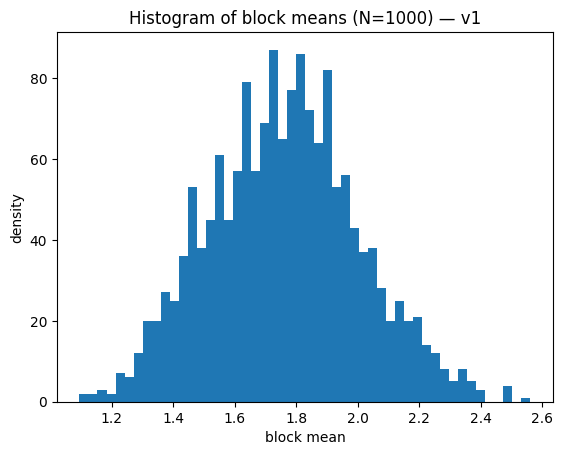

for (k,N)=(0, 1000): True mean= 1.7608399300643245, mean of sample means=1.76084, sigma of sample means=0.243042


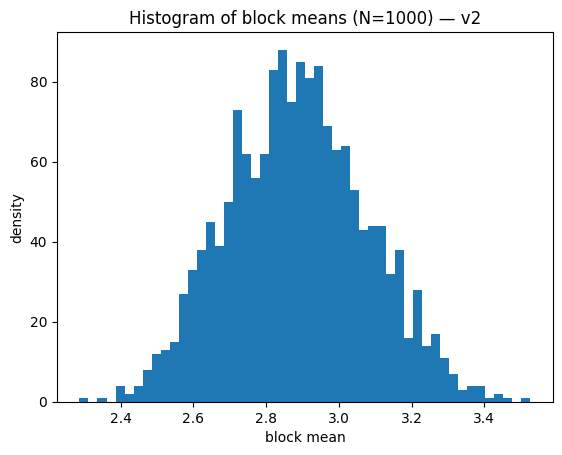

for (k,N)=(1, 1000): True mean= 2.886344221395855, mean of sample means=2.88634, sigma of sample means=0.192884


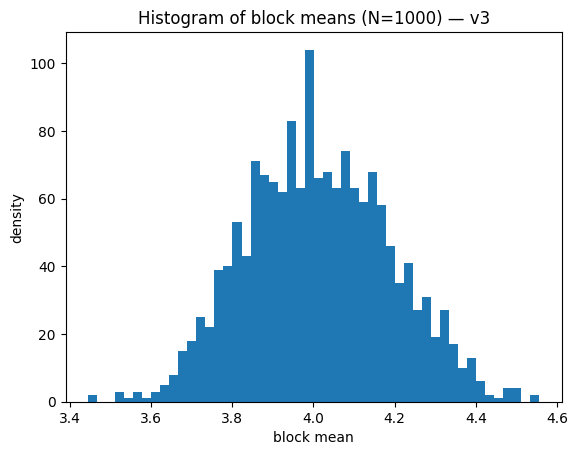

for (k,N)=(2, 1000): True mean= 4.011848512727643, mean of sample means=4.01185, sigma of sample means=0.177


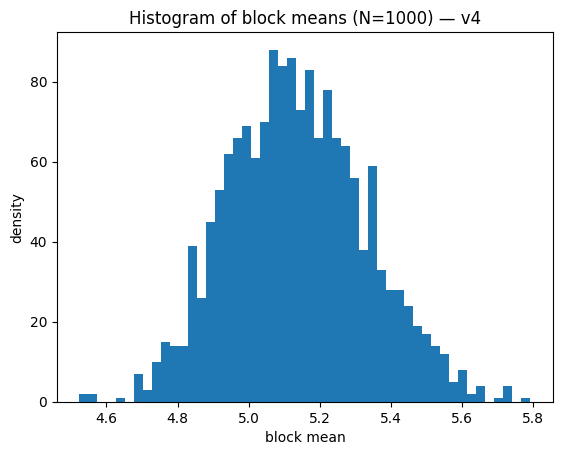

for (k,N)=(3, 1000): True mean= 5.137116475044711, mean of sample means=5.13712, sigma of sample means=0.194217


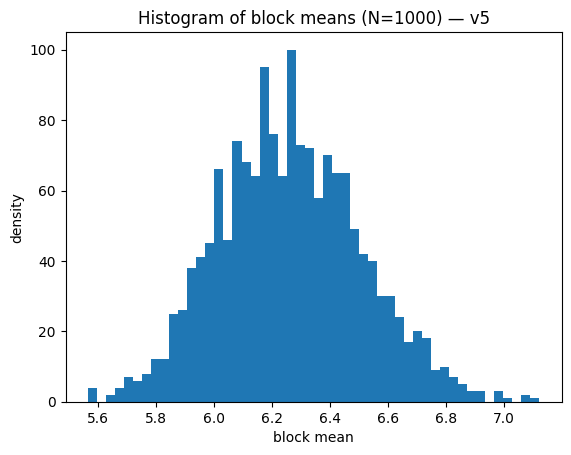

for (k,N)=(4, 1000): True mean= 6.262384437362061, mean of sample means=6.26238, sigma of sample means=0.245569


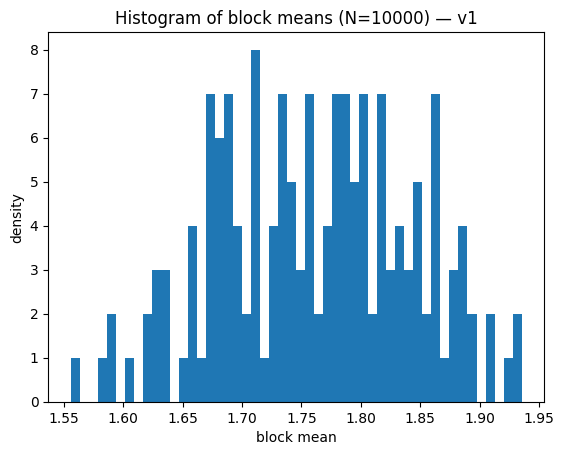

for (k,N)=(0, 10000): True mean= 1.7608399300643245, mean of sample means=1.76084, sigma of sample means=0.0814716


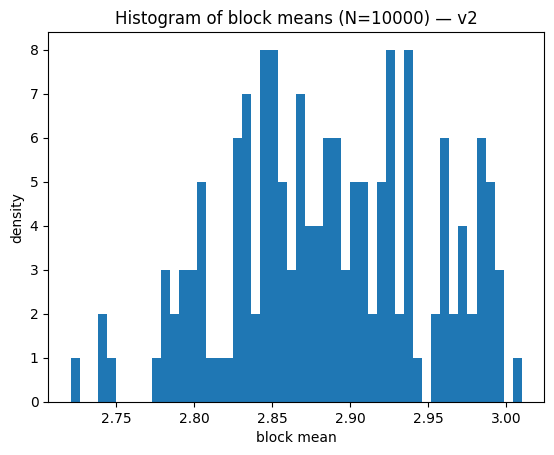

for (k,N)=(1, 10000): True mean= 2.886344221395855, mean of sample means=2.88634, sigma of sample means=0.0636673


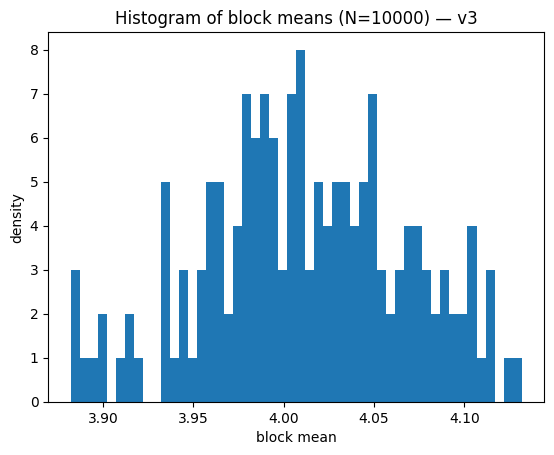

for (k,N)=(2, 10000): True mean= 4.011848512727643, mean of sample means=4.01185, sigma of sample means=0.0558912


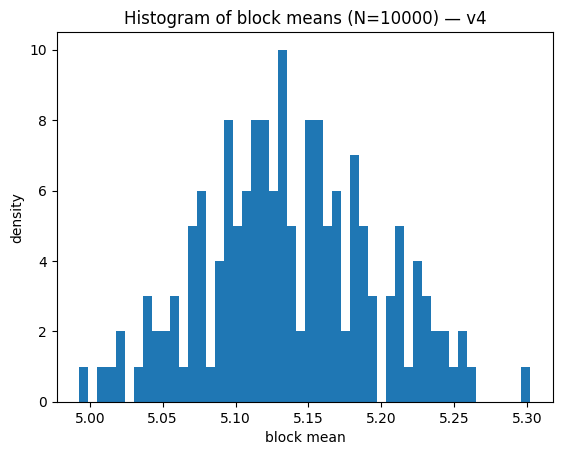

for (k,N)=(3, 10000): True mean= 5.137116475044711, mean of sample means=5.13712, sigma of sample means=0.058825


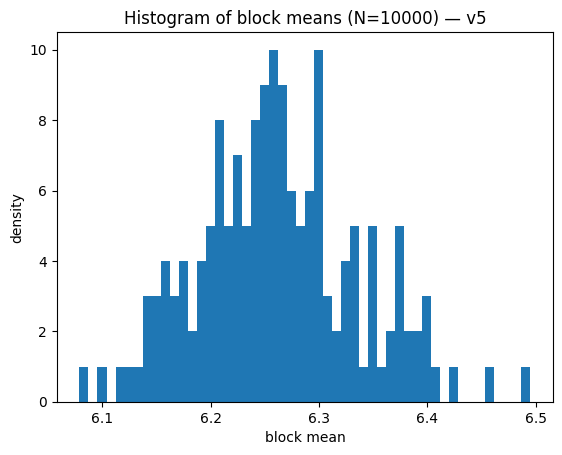

for (k,N)=(4, 10000): True mean= 6.262384437362061, mean of sample means=6.26238, sigma of sample means=0.074013


In [5]:
N1, N2 = 1000, 10000
s1 = analyze_sample_means(X, N1)
s2 = analyze_sample_means(X, N2)

In [6]:
print("standard deviation of the means:")
print(f"s1 (N={N1}): {s1}")
print(f"s2 (N={N2}): {s2}")

ratio = s1 / s2
expected = np.sqrt(N2 / N1)
print("\nColumn-wise ratio sigma(N1)/sigma(N2):", ratio)
print(f"Expected ratio ≈ sqrt({N2}/{N1}) = {expected:.3f}")
print("two values do show correct behavior with N")


standard deviation of the means:
s1 (N=1000): [0.24304186 0.19288382 0.17699971 0.19421743 0.24556898]
s2 (N=10000): [0.08147157 0.06366727 0.0558912  0.05882505 0.07401296]

Column-wise ratio sigma(N1)/sigma(N2): [2.98314943 3.02956012 3.1668618  3.30161113 3.3179187 ]
Expected ratio ≈ sqrt(10000/1000) = 3.162
two values do show correct behavior with N


1.3)

In [7]:
def acf(X, ncut):
    """
    Returns normalized  rho ACF: C(n), shape (ncut+1, A).
    """
    M, A = X.shape
    ncut = min(int(ncut), M - 1)

    mu = X.mean(axis=0, keepdims=True)
    Xc = X - mu

    C = np.empty((ncut + 1, A), dtype=np.float64)
    for n in range(ncut + 1):
        prod = Xc[:M - n, :] * Xc[n:, :]
        C[n, :] = prod.sum(axis=0) / (M - n)
    C0 = C[0, :]
    rho  = C/C0
    return rho,C,C0



In [8]:

rho,C,C0 = acf(X,ncut = 1000)


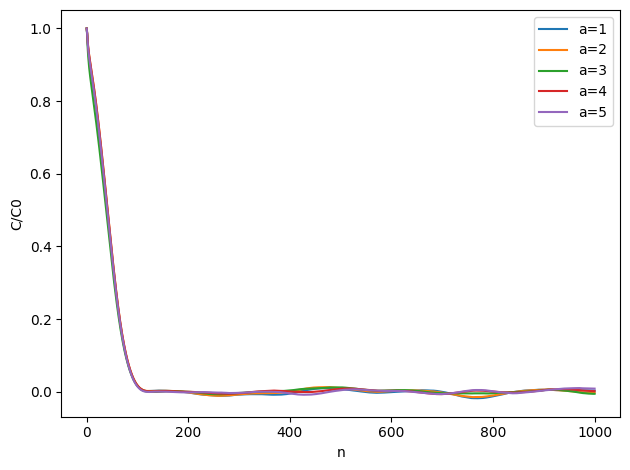

In [9]:


ns = np.arange(rho.shape[0])
for k in range(X.shape[1]):
    plt.plot(ns, rho[:, k], label=f"a={k+1}")
plt.xlabel("n")
plt.ylabel("C/C0")
plt.legend()
plt.tight_layout()
plt.show()

1.4)

In [10]:
def get_tau_int(rho,ncut):
  tau_ints = 0.5 + rho[1:ncut+1, :].sum(axis=0)
  return tau_ints



In [11]:
for ncut in range(0,300,10):
  tau_ints = get_tau_int(rho,ncut=ncut)
  print(f"ncut = {ncut}, tau_ints:  {tau_ints}")

ncut = 0, tau_ints:  [0.5 0.5 0.5 0.5 0.5]
ncut = 10, tau_ints:  [9.68762916 9.74411338 9.42516122 9.73903887 9.68298928]
ncut = 20, tau_ints:  [17.8447198  17.99040667 17.18589536 17.97932478 17.8344168 ]
ncut = 30, tau_ints:  [24.85551951 25.09715217 23.81276693 25.08252763 24.84364322]
ncut = 40, tau_ints:  [30.5546608  30.88703525 29.18275409 30.86484119 30.54024581]
ncut = 50, tau_ints:  [34.88363179 35.29415802 33.25332595 35.26285608 34.86442771]
ncut = 60, tau_ints:  [37.91066424 38.38691811 36.10644072 38.35169782 37.89077073]
ncut = 70, tau_ints:  [39.84284025 40.37169988 37.9407327  40.33622517 39.82360979]
ncut = 80, tau_ints:  [40.97364096 41.5404109  39.02135083 41.50456351 40.94951191]
ncut = 90, tau_ints:  [41.56745009 42.15882534 39.59111019 42.1193763  41.52910658]
ncut = 100, tau_ints:  [41.83142799 42.43866475 39.8448591  42.39290484 41.77207029]
ncut = 110, tau_ints:  [41.92157706 42.53981866 39.93169211 42.48880463 41.84188947]
ncut = 120, tau_ints:  [41.94775934 

1.5)

In [12]:
# chosen ncut by inspection
ncut = 200
sigma2_va = X.var(axis=0, ddof=1)     
sigma_va   = np.sqrt(sigma2_va) 
print(f"true standard deviation: ", sigma_va)      
Ns = [1000, 10000]
tau_ints = get_tau_int(rho,ncut=ncut)

for N in Ns:
    # true std of the means 
    sigma_va_N_emp = analyze_sample_means(X, N,plot=False)  
    # from tau_int                   
    sigma_va_N_the = np.sqrt(2.0 * tau_ints / N) * sigma_va        
    
    rel_err = (sigma_va_N_emp - sigma_va_N_the) / sigma_va_N_the

    print(f"N = {N}")
    for a in range(X.shape[1]):
        print(f"a={a+1}:  true std from means ={sigma_va_N_emp[a]}   from tau_int={sigma_va_N_the[a]}  rel_err={rel_err[a]*100}%")
print("Small errors -> relation holds")

true standard deviation:  [0.86683585 0.6795499  0.63770906 0.67618473 0.86180775]
N = 1000
a=1:  true std from means =0.24304185717322568   from tau_int=0.25147965408842277  rel_err=-3.3552602677870182%
a=2:  true std from means =0.19288381908995536   from tau_int=0.19860174740972897  rel_err=-2.879092653690066%
a=3:  true std from means =0.17699970941678678   from tau_int=0.18037489860234396  rel_err=-1.8712078075775678%
a=4:  true std from means =0.19421743144952955   from tau_int=0.19737983875912957  rel_err=-1.6021936837526902%
a=5:  true std from means =0.24556897738208971   from tau_int=0.24918907561264123  rel_err=-1.4527515789572056%
N = 10000
a=1:  true std from means =0.08147156652698676   from tau_int=0.07952484921106909  rel_err=2.447935878194288%
a=2:  true std from means =0.06366726891447179   from tau_int=0.06280338691041891  rel_err=1.3755341018233584%
a=3:  true std from means =0.05589120106104133   from tau_int=0.05703955123053289  rel_err=-2.0132524620510246%
a=4:  

1.6)

In [13]:
def norm_covariance(X):
  M,A = X.shape
  means = X.mean(axis=0)
  Xc = X - means
  C = (Xc.T @ Xc) / M 
  sigmas = np.sqrt(np.diag(C))      
  rho = C / np.outer(sigmas,sigmas)       
  return rho     
rho = norm_covariance(X)
print("Normalized Covariance: ", rho)



Normalized Covariance:  [[1.00000000e+00 9.30249237e-01 6.23271233e-01 2.93947421e-01
  6.93888642e-05]
 [9.30249237e-01 1.00000000e+00 8.66737602e-01 5.93589801e-01
  2.90118407e-01]
 [6.23271233e-01 8.66737602e-01 1.00000000e+00 8.65510082e-01
  6.18212514e-01]
 [2.93947421e-01 5.93589801e-01 8.65510082e-01 1.00000000e+00
  9.28775393e-01]
 [6.93888642e-05 2.90118407e-01 6.18212514e-01 9.28775393e-01
  1.00000000e+00]]


1.7)

In [14]:
Ns = [1000,10000]
ncuts = [75,100]
for i in range(len(Ns)):
  print(f"N={Ns[i]}")
  X_sim = X[:Ns[i],:]
  rho,C,C0 = acf(X_sim,ncut=1000)
  for n in range(0,500,10):
    tau_ints =  get_tau_int(rho,ncut=n)
    print(f"n: {n}, {tau_ints}")

N=1000
n: 0, [0.5 0.5 0.5 0.5 0.5]
n: 10, [9.68297607 9.74077403 9.47766571 9.79138876 9.76822779]
n: 20, [17.9680154  18.06392858 17.2023732  17.76086523 17.67400086]
n: 30, [24.96605671 25.25971275 23.90024489 24.10451956 23.72669263]
n: 40, [30.38203065 31.00562094 29.34750116 28.54390287 27.55415225]
n: 50, [34.15094146 35.20977503 33.41352852 31.01132732 29.17586423]
n: 60, [36.203422   37.92716751 36.11316432 31.66706745 28.73110741]
n: 70, [36.78634797 39.41327981 37.69127231 30.89984261 26.67095361]
n: 80, [35.97588803 39.94432694 38.71598963 29.2887221  23.54815509]
n: 90, [34.05945013 39.76208183 39.45371065 27.37917608 19.95236035]
n: 100, [31.33751903 39.07173102 39.96358284 25.60580495 16.63761852]
n: 110, [28.11724055 37.96192472 40.09540222 24.12823037 13.92727716]
n: 120, [24.59193563 36.48422603 39.92321605 22.92892426 11.88823527]
n: 130, [20.92975244 34.73631131 39.5616673  21.87109166 10.33271179]
n: 140, [17.53666137 32.70064563 38.57378797 20.59645245  8.9438574 ]

In [15]:
Ns = [1000,10000]
# choose n_cuts from inspection
ncuts = [60,100]
for i in range(len(Ns)):
  X_sim = X[:Ns[i],:]
  rho,C,C0 = acf(X_sim,ncut=1000)
  tau_ints =  get_tau_int(rho,ncut=ncuts[i])
  sigma_N_bar_sim = np.sqrt(2.0 * tau_ints / Ns[i]) * X_sim.std(axis=0) 
  sigma_N_bar_universe = analyze_sample_means(X, Ns[i],plot=False)  
  rel_err_ptc = 100*(sigma_N_bar_sim - sigma_N_bar_universe) / sigma_N_bar_universe
                   

  rho_N = norm_covariance(X_sim) 


  print(f"\nN={Ns[i]}, ncut={ncuts[i]}")
  print("tau_int:", tau_ints)
  print("predicted sigma_bar(N) from group", sigma_N_bar_sim)
  print("sigma_bar(N) from universe", sigma_N_bar_universe)
  print("relative err_pct (%):, ",rel_err_ptc)
  print("sample correlation matrix:")
  for row in rho_N:
    print(" ".join(f"{x: .6f}" for x in row))
  print("universe correlation matrix:")
  for row in norm_covariance(X):
    print(" ".join(f"{x: .6f}" for x in row))




N=1000, ncut=60
tau_int: [36.203422   37.92716751 36.11316432 31.66706745 28.73110741]
predicted sigma_bar(N) from group [0.22314647 0.17965893 0.17455603 0.18805268 0.23211876]
sigma_bar(N) from universe [0.24304186 0.19288382 0.17699971 0.19421743 0.24556898]
relative err_pct (%):,  [-8.18599183 -6.85640044 -1.38061398 -3.17414887 -5.47716287]
sample correlation matrix:
 1.000000  0.909464  0.550012  0.215428 -0.036440
 0.909464  1.000000  0.847460  0.577426  0.322742
 0.550012  0.847460  1.000000  0.884787  0.694797
 0.215428  0.577426  0.884787  1.000000  0.949894
-0.036440  0.322742  0.694797  0.949894  1.000000
universe correlation matrix:
 1.000000  0.930249  0.623271  0.293947  0.000069
 0.930249  1.000000  0.866738  0.593590  0.290118
 0.623271  0.866738  1.000000  0.865510  0.618213
 0.293947  0.593590  0.865510  1.000000  0.928775
 0.000069  0.290118  0.618213  0.928775  1.000000

N=10000, ncut=100
tau_int: [41.70860314 41.88367342 39.05332613 43.38665493 44.47033522]
predi

JACKKNIFE ANALYSIS

2.1)

In [16]:

M, A = X.shape
N = 5000
num_blocks = M // N
X_copy = X[:]

X_blocks = X_copy.reshape(num_blocks, N, A)

block_means = X_blocks.mean(axis=1)

f1_vals = block_means[:, 0] / block_means[:, 1]
f2_vals = np.exp(block_means[:, 2] - block_means[:, 3])

sigma_f1_univ = f1_vals.std(ddof=1)
sigma_f2_univ = f2_vals.std(ddof=1)
print(f"(Universe) num_blocks={num_blocks}, N={N}")
print("sigma_f1_universe =", sigma_f1_univ)
print("sigma_f2_universe =", sigma_f2_univ)

(Universe) num_blocks=320, N=5000
sigma_f1_universe = 0.02143031264154101
sigma_f2_universe = 0.012691517000371471


2.2

In [17]:


sbar = block_means.std(axis=0)   

mu = block_means.mean(axis=0)            
mu1, mu2, mu3, mu4 = mu[0], mu[1], mu[2], mu[3]
s1,  s2,  s3,  s4  = sbar[0], sbar[1], sbar[2], sbar[3]

f1 = mu1 / mu2
f2 = np.exp(mu3 - mu4)

sigma_f1_naive = np.sqrt((s1/mu2)**2 + ((mu1/mu2**2)*s2)**2)
sigma_f2_naive = f2 * np.sqrt(s3**2 + s4**2)

print("naive sigma_f1:", sigma_f1_naive)
print("naive sigma_f2:", sigma_f2_naive)

naive sigma_f1: 0.04144653593212974
naive sigma_f2: 0.039167756616268264


2.3)

In [18]:
XN = X[:N,:]


def bin_means(XN, b):
 
    N, A = XN.shape
    B = N // b
    X_trim = XN[:B*b]                   
    return X_trim.reshape(B, b, A).mean(axis=1)  # (B, A)

def jackknife__means(B_means):

    B, A = B_means.shape
    total = B_means.sum(axis=0)         # (A,)
    jk_vals = (total - B_means) / (B - 1)  # (B,A)
    return jk_vals
# choose b from inspection and around t_int
b = 100
B = N//b
B_means = bin_means(XN,b=b)
jk_vals = jackknife__means(B_means)

va_bar = jk_vals.mean(axis=0)
sigma_va_bar_N = np.sum((jk_vals-va_bar)**2,axis=0)*(B-1)/B
print("from jackknife values:")
print("va_bar: ", va_bar)
print("sigma_va_bar_N: ",sigma_va_bar_N)



from jackknife values:
va_bar:  [1.65199065 2.80054069 3.94909073 5.13281684 6.31654296]
sigma_va_bar_N:  [0.00797883 0.00500744 0.0043859  0.00554824 0.00906802]


2.4)

In [19]:
f1_jk_vals = jk_vals[:, 0] / jk_vals[:, 1]
f2_jk_vals = np.exp(jk_vals[:, 2] - jk_vals[:, 3])
sigma_f1_jk = np.sqrt(np.sum((f1_jk_vals - np.mean(f1_jk_vals))**2)*(B-1)/B)
sigma_f2_jk = np.sqrt(np.sum((f2_jk_vals - np.mean(f2_jk_vals))**2)*(B-1)/B)
print("sigma_f1_jk: ",sigma_f1_jk)
print("sigma_f2_jk: ",sigma_f2_jk)
print("Compared to universal error")
print("sigma_f1_universe =", sigma_f1_univ)
print("sigma_f2_universe =", sigma_f2_univ)
print("jacknife errors mmatch universal errors")

sigma_f1_jk:  0.018749317884849792
sigma_f2_jk:  0.010497460466550519
Compared to universal error
sigma_f1_universe = 0.02143031264154101
sigma_f2_universe = 0.012691517000371471
jacknife errors mmatch universal errors


ARGON MD


-3056.597238122859
(2001, 864, 3)


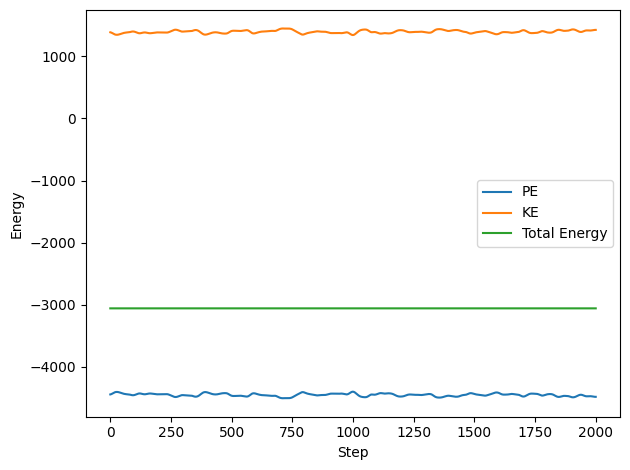

In [20]:
# Unnload MD data after thermalization and plot, 1 data point per step
import matplotlib.pyplot as plt
N = 864
rho = 0.75
L = (N / rho) ** (1/3)
V = float(L)**3

file_path = 'MD_results_for_stat_analysis_2025-10-12_23:09:50.npz'
def unload_from_npz(path):

  with np.load(path, allow_pickle=True) as d:
      pos = d["pos"]         
      vel = d["vel"]          
      steps = d["steps"] 

    
      PEs, KEs, TEs = d["PEs"], d["KEs"], d["TEs"]
      Forces = d["Forces"]
  return pos, vel, steps, Forces,PEs, KEs,TEs

pos_file, vel_file, steps_file, Forces,PEs, KEs,TEs  = unload_from_npz(file_path)
print(TEs[-1])
print(pos_file.shape)
plt.figure()
plt.plot(steps_file, PEs, label='PE')
plt.plot(steps_file, KEs, label='KE')
plt.plot(steps_file, TEs, label='Total Energy')
plt.xlabel('Step')
plt.ylabel('Energy')
plt.legend()
plt.tight_layout()
plt.show()



In [21]:
# construct data object that contains T,PE,G and plot ACF
def temp(vel,N):
    return (16.0 / N) * np.sum(vel * vel)
def r_ij_matrix(pos, L):
    Nloc = pos.shape[0]
    d = pos.reshape(Nloc, 1, 3) - pos.reshape(1, Nloc, 3)
    d -= L * np.around(d / L)  
    return d

def virial(pos, L):

    d  = r_ij_matrix(pos, L)           # (N,N,3)
    r2 = np.sum(d*d, axis=2)           # (N,N)
    np.fill_diagonal(r2, np.inf)

    iu = np.triu_indices(pos.shape[0], 1)  # i<j
    invr2 = 1.0 / r2[iu]
    invr6 = invr2**3
    g_pairs = (invr6**2) - 0.5*invr6
    return np.sum(g_pairs)
# def virial(pos, forces):
#     assert pos.shape == forces.shape and pos.shape[1] == 3
#     return float(np.sum(pos * forces))  

G = [virial(pos_file[i],L) for i in range(len(pos_file))]
T = [temp(vel_file[i],N) for i in range(len(pos_file))]

print(T)
print(G)
print(PEs)






[1.0684092924295467, 1.067742928286106, 1.06691619023828, 1.0659326740247927, 1.0647991350203414, 1.0635253704631973, 1.0621240620954404, 1.060610587061335, 1.0590027945515006, 1.0573207321672067, 1.0555863262846117, 1.0538229793319094, 1.0520550941608207, 1.0503074908112382, 1.0486047324114052, 1.0469704035577285, 1.045426350787827, 1.043991957202337, 1.0426835057931738, 1.0415137054785377, 1.04049143612157, 1.039621707326227, 1.0389058672329294, 1.0383420281735696, 1.0379256429917816, 1.0376501820002277, 1.0375078262102195, 1.0374901423463787, 1.0375886749985064, 1.0377954065369912, 1.0381030791087487, 1.0385053547187955, 1.0389968178686206, 1.0395728402357576, 1.040229322775012, 1.040962337018489, 1.0417677186437062, 1.0426406465810807, 1.0435752639837668, 1.0445643973596674, 1.0455994066237286, 1.046670224186655, 1.0477655984196355, 1.0488735089150167, 1.0499817254974824, 1.0510784574893142, 1.0521530160519283, 1.0531963939706328, 1.0542016956408957, 1.0551643726558435, 1.056082215

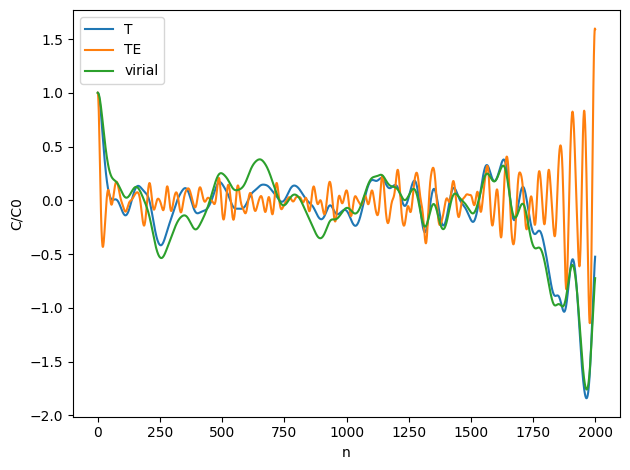

T is identical to PE
ncut :0, [0.5 0.5 0.5]
ncut :1, [1.49861632 1.48835098 1.49899132]
ncut :2, [2.49315465 2.44296574 2.49523012]
ncut :3, [3.48095827 3.34311145 3.48699305]
ncut :4, [4.45943315 4.17021197 4.47259097]
ncut :5, [5.42607174 4.90851552 5.45038198]
ncut :6, [6.37847496 5.54559032 6.41878358]
ncut :7, [7.31437209 6.07262945 7.37628377]
ncut :8, [8.23163806 6.4845591  8.32145097]
ncut :9, [9.12830822 6.77996209 9.2529425 ]
ncut :10, [10.00259006  6.96083793 10.16951175]
ncut :11, [10.85287219  7.03223029 11.07001379]
ncut :12, [11.67773033  7.00176002 11.9534096 ]
ncut :13, [12.47593054  6.87909836 12.81876887]
ncut :14, [13.24642985  6.67541786 13.66527136]
ncut :15, [13.9883744   6.40285194 14.49220712]
ncut :16, [14.70109542  6.07399026 15.29897546]
ncut :17, [15.38410326  5.70142895 16.08508288]
ncut :18, [16.03707983  5.29738807 16.85014008]
ncut :19, [16.65986952  4.87340748 17.59385824]
ncut :20, [17.25246921  4.4401194  18.31604452]
ncut :21, [17.81501732  4.007096

In [25]:
X_MD = np.column_stack([np.array(T),np.array(TEs),np.array(G)]) # (2001 x 3)
M,A = X_MD.shape
ncut=100
rho_MD,C,C0 = acf(X_MD,ncut=2000)
lags = np.arange(rho_MD.shape[0])
labels = ["T", "TE", "virial"]
for k in range(X_MD.shape[1]):
    plt.plot(lags[:2000], rho_MD[:2000, k], label=f"{labels[k]}")
plt.xlabel("n"); plt.ylabel("C/C0")
plt.legend()
plt.tight_layout()
plt.show()
print("T is identical to PE")

M,A = X_MD.shape
for ncut in range(2000):
    tau_ints = get_tau_int(rho_MD,ncut=ncut)
    print(f"ncut :{ncut}, {tau_ints}")


In [26]:
# get error bars for T, PE, G using tau_int, get covariance matrix
# choose ncut  by inspection
ncut = 50
tau_ints = get_tau_int(rho_MD,ncut=ncut)
sigma_N_bar= np.sqrt(2.0 * tau_ints / M) * X_MD.std(axis=0) 
sample_means = X_MD.mean(axis=0)

for i in range(X_MD.shape[1]):
  print(f"{labels[i]}={sample_means[i]}+-{sigma_N_bar[i]}")
print("mean PE: ", PEs.mean(axis=0))
print("mean KE: ", KEs.mean(axis=0))

rho_MD = norm_covariance(X_MD)
print("Normalized Covariance: ", rho_MD)
print(KEs[-1])


T=1.0742492510496051+-0.002617103623258812
TE=-3056.5910663117684+-0.0002668075379186166
virial=-9.095387155005415+-1.6053384619143316
mean PE:  -4448.818095672057
mean KE:  1392.2270293602894
Normalized Covariance:  [[ 1.         -0.44584913 -0.94998847]
 [-0.44584913  1.          0.35484431]
 [-0.94998847  0.35484431  1.        ]]
1423.2436885194734


In [24]:
# use jacknife method to calculate pressure with error bars

def pressure_from_virial(G, N, L, T):
    V = float(L)**3
    rho = N / V
    return rho * T + (G / (3.0 * V))

def jackknife__means(B_means):

    B, A = B_means.shape
    total = B_means.sum(axis=0)         # (A,)
    jk_vals = (total - B_means) / (B - 1)  
    return jk_vals
rho=0.75

bin_means_MD = bin_means(X_MD,b=ncut)
B = bin_means_MD.shape[0]
jk_vals = jackknife__means(bin_means_MD)
P_jk = rho*jk_vals[:,0]+(jk_vals[:,2]/(3.0*V))
P_jk_mean = np.mean(P_jk)
sigma_P_jk = np.sqrt(np.sum((P_jk - np.mean(P_jk))**2)*(B-1)/B)
print(f"Pressure  = {P_jk_mean}+-{sigma_P_jk}")



Pressure  = 0.8030482046635716+-0.0012438981585635128
